In [2]:
%pip install pandas

  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl (10.9 MB)
Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl (12.7 MB)

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---

In [3]:
import sqlite3
import pandas as pd
import urllib.request

# Download and connect to the database
url = "https://raw.githubusercontent.com/lerocha/chinook-database/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite"
urllib.request.urlretrieve(url, "chinook.db")
conn = sqlite3.connect("chinook.db")

# Verify connection by listing tables
query = "SELECT name FROM sqlite_master WHERE type='table';"
tables = pd.read_sql_query(query, conn)
print(tables)

             name
0           Album
1          Artist
2        Customer
3        Employee
4           Genre
5         Invoice
6     InvoiceLine
7       MediaType
8        Playlist
9   PlaylistTrack
10          Track


In [4]:
# 1. Multi-Table JOIN: Which countries generate the most revenue?
query_1 = """
SELECT 
    BillingCountry AS Country,
    COUNT(InvoiceId) AS Total_Orders,
    SUM(Total) AS Total_Revenue
FROM Invoice
GROUP BY BillingCountry
ORDER BY Total_Revenue DESC
LIMIT 5;
"""
revenue_by_country = pd.read_sql_query(query_1, conn)
print("--- Top 5 Countries by Revenue ---")
print(revenue_by_country, "\n")

# 2. INNER JOIN across 4 tables: Who are the top-selling artists?
query_2 = """
SELECT 
    ar.Name AS Artist_Name,
    COUNT(il.Quantity) AS Tracks_Sold,
    SUM(il.UnitPrice * il.Quantity) AS Total_Sales
FROM Artist ar
JOIN Album al ON ar.ArtistId = al.ArtistId
JOIN Track t ON al.AlbumId = t.AlbumId
JOIN InvoiceLine il ON t.TrackId = il.TrackId
GROUP BY ar.Name
ORDER BY Total_Sales DESC
LIMIT 5;
"""
top_artists = pd.read_sql_query(query_2, conn)
print("--- Top 5 Selling Artists ---")
print(top_artists, "\n")

# 3. Subquery / Advanced Logic: What is the average order value per customer?
query_3 = """
SELECT 
    c.FirstName || ' ' || c.LastName AS Customer_Name,
    COUNT(i.InvoiceId) AS Number_of_Purchases,
    ROUND(AVG(i.Total), 2) AS Average_Order_Value,
    SUM(i.Total) AS Total_Spent
FROM Customer c
JOIN Invoice i ON c.CustomerId = i.CustomerId
GROUP BY c.CustomerId
ORDER BY Total_Spent DESC
LIMIT 5;
"""
customer_ltv = pd.read_sql_query(query_3, conn)
print("--- Top 5 Customers by Lifetime Value ---")
print(customer_ltv)

--- Top 5 Countries by Revenue ---
   Country  Total_Orders  Total_Revenue
0      USA            91         523.06
1   Canada            56         303.96
2   France            35         195.10
3   Brazil            35         190.10
4  Germany            28         156.48 

--- Top 5 Selling Artists ---
    Artist_Name  Tracks_Sold  Total_Sales
0   Iron Maiden          140       138.60
1            U2          107       105.93
2     Metallica           91        90.09
3  Led Zeppelin           87        86.13
4          Lost           41        81.59 

--- Top 5 Customers by Lifetime Value ---
        Customer_Name  Number_of_Purchases  Average_Order_Value  Total_Spent
0         Helena Holý                    7                 7.09        49.62
1  Richard Cunningham                    7                 6.80        47.62
2          Luis Rojas                    7                 6.66        46.62
3     Ladislav Kovács                    7                 6.52        45.62
4       Hugh

In [6]:
%pip install matplotlib seaborn

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
U

C:\Users\konto\AppData\Local\Temp\ipykernel_12240\2413355366.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=revenue_by_country, x='Country', y='Total_Revenue', ax=axes[0], palette='Blues_r')
C:\Users\konto\AppData\Local\Temp\ipykernel_12240\2413355366.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_artists, y='Artist_Name', x='Total_Sales', ax=axes[1], palette='Oranges_r')


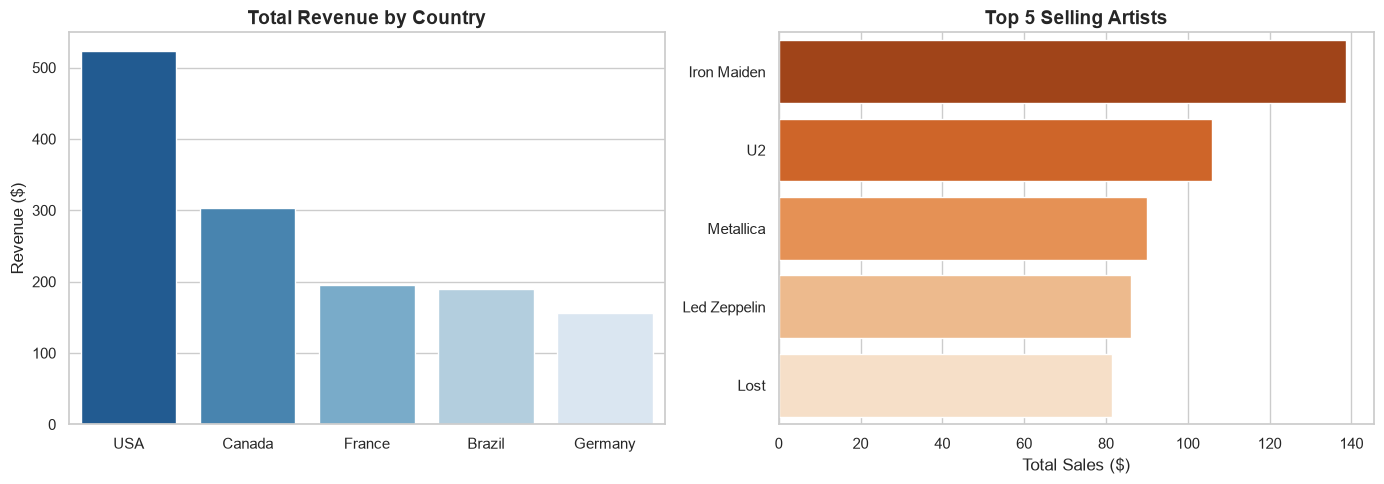

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the visual style
sns.set_theme(style="whitegrid")

# Create a wide canvas for two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Revenue by Country (Vertical Bar Chart)
sns.barplot(data=revenue_by_country, x='Country', y='Total_Revenue', ax=axes[0], palette='Blues_r')
axes[0].set_title('Total Revenue by Country', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Revenue ($)')
axes[0].set_xlabel('')

# Chart 2: Top Selling Artists (Horizontal Bar Chart)
sns.barplot(data=top_artists, y='Artist_Name', x='Total_Sales', ax=axes[1], palette='Oranges_r')
axes[1].set_title('Top 5 Selling Artists', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Sales ($)')
axes[1].set_ylabel('')

# Display the dashboard
plt.tight_layout()
plt.show()